## Chargement du dataset Twitter arabe

Cette étape consiste à importer la base de données **Twitter Data for Arabic Sentiment Analysis** depuis l’organisation locale des fichiers.

Le dataset est structuré en deux dossiers :

- **Positive/** : tweets annotés comme positifs  
- **Negative/** : tweets annotés comme négatifs  


In [38]:
import os
import pandas as pd

def load_twitter_dataset(base_path="./archive/Twitter"):
    data = []
    
    for label in ["Positive", "Negative"]:
        folder = os.path.join(base_path, label)

        if not os.path.exists(folder):
            print(f"Dossier introuvable: {folder}")
            continue
        
        print(f"Chargement des fichiers {label}...")

        for filename in os.listdir(folder):
            filepath = os.path.join(folder, filename)

            # On charge seulement les fichiers réguliers
            if not os.path.isfile(filepath):
                continue

            try:
                with open(filepath, "r", encoding="utf-8", errors="ignore") as f:
                    text = f.read().strip()

                #  NE PAS IGNORER LES FICHIERS VIDES
                data.append([text, label])

            except Exception as e:
                print(f"Erreur fichier {filename}: {e}")

    df = pd.DataFrame(data, columns=["text", "label"])
    return df


df = load_twitter_dataset()

print("=" * 50)
print("CHARGEMENT TERMINÉ")
print("=" * 50)
print(f"Taille du dataset : {df.shape}")
print(df.label.value_counts())
df.head()


Chargement des fichiers Positive...
Chargement des fichiers Negative...
CHARGEMENT TERMINÉ
Taille du dataset : (2000, 2)
label
Positive    1000
Negative    1000
Name: count, dtype: int64


,text,label
0,﻿حقا,Positive
1,صح جدا,Positive
2,﻿اه و النعمة,Positive
3,كلامك جميل ورائع,Positive
4,﻿و خير الكلام ما قل و دل,Positive


## Analyse exploratoire du dataset (Exploratory Data Analysis – EDA)

Avant de procéder au prétraitement et à la modélisation, une **analyse exploratoire** du corpus est réalisée afin de :

- Vérifier l’**équilibre des classes** (tweets positifs vs négatifs),
- Observer la **distribution de la longueur des tweets**,
- Identifier la **variabilité du contenu textuel**.

Cette étape permet de mieux comprendre la structure du dataset et d’anticiper les choix de traitement linguistique et de vectorisation.

Les visualisations suivantes sont générées :

1. **Histogramme de distribution des sentiments** : nombre de tweets par classe.
2. **Histogramme des longueurs de textes** : répartition des tailles de tweets en caractères.

Des **statistiques descriptives** sont également calculées :

- longueur moyenne
- longueur minimale
- longueur maximale
- écart-type

Enfin, quelques exemples de tweets sont affichés pour illustrer la diversité du corpus et vérifier la qualité des données collectées.


 ANALYSE EXPLORATOIRE
Distribution des sentiments :
label
Positive    1000
Negative    1000
Name: count, dtype: int64


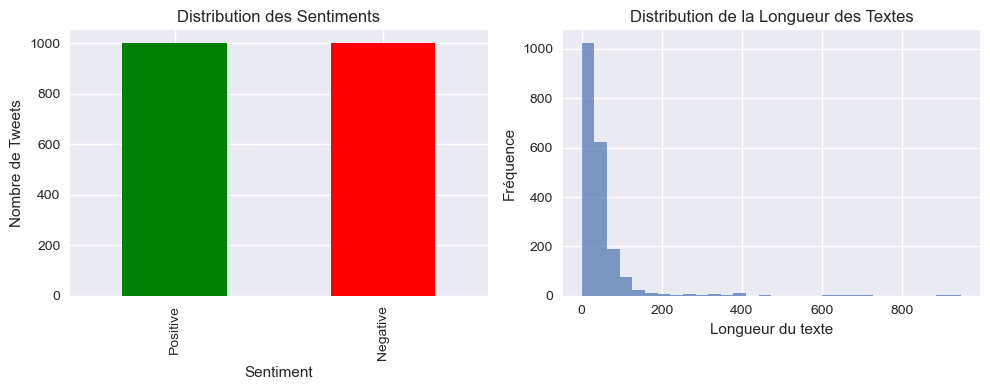


 Statistiques des longueurs de texte :
Longueur moyenne : 47.36 caractères
Longueur maximale : 948 caractères
Longueur minimale : 0 caractères
Écart-type : 67.68

 Exemples de tweets :
POSITIVE - Tweet 1:
   ﻿حقا

POSITIVE - Tweet 2:
   صح جدا

POSITIVE - Tweet 3:
   ﻿اه و النعمة



In [39]:
# Analyse approfondie du dataset
import matplotlib.pyplot as plt
print(" ANALYSE EXPLORATOIRE")
print("=" * 40)

# Distribution des labels
label_counts = df['label'].value_counts()
print("Distribution des sentiments :")
print(label_counts)


plt.figure(figsize=(10, 4))

# Graphique 1: Distribution des sentiments
plt.subplot(1, 2, 1)
label_counts.plot(kind='bar', color=['green', 'red'])
plt.title('Distribution des Sentiments')
plt.xlabel('Sentiment')
plt.ylabel('Nombre de Tweets')

# Graphique 2: Longueur des textes
plt.subplot(1, 2, 2)
df['text_length'] = df['text'].apply(len)
df['text_length'].hist(bins=30, alpha=0.7)
plt.title('Distribution de la Longueur des Textes')
plt.xlabel('Longueur du texte')
plt.ylabel('Fréquence')

plt.tight_layout()
plt.show()

# Statistiques détaillées
print(f"\n Statistiques des longueurs de texte :")
print(f"Longueur moyenne : {df['text_length'].mean():.2f} caractères")
print(f"Longueur maximale : {df['text_length'].max()} caractères")
print(f"Longueur minimale : {df['text_length'].min()} caractères")
print(f"Écart-type : {df['text_length'].std():.2f}")

# Aperçu de quelques tweets
print(f"\n Exemples de tweets :")
print("=" * 40)
for i, (text, label) in enumerate(zip(df['text'].head(3), df['label'].head(3))):
    print(f"{label.upper()} - Tweet {i+1}:")
    print(f"   {text[:100]}..." if len(text) > 100 else f"   {text}")
    print()

## Prétraitement linguistique des tweets arabes

Les tweets collectés contiennent naturellement du bruit :  
URLs, mentions, hashtags, chiffres, ponctuation, lettres latines, répétitions de caractères et variations orthographiques propres à l’arabe.

Avant l’étape de modélisation, un **pipeline complet de nettoyage linguistique** est mis en œuvre afin de transformer le texte brut en une représentation exploitable par les algorithmes de Machine Learning.


Le dataset nettoyé est ensuite exporté au format CSV pour être utilisé lors des étapes de vectorisation et d’apprentissage.


In [40]:
import re
import pandas as pd
from collections import Counter

# =========================================
# FONCTIONS DE PRÉTRAITEMENT AMÉLIORÉES
# =========================================

class ArabicTextPreprocessor:
    def __init__(self):
        self.arabic_diacritics = re.compile(""" ّ|َ|ً|ُ|ٌ|ِ|ٍ|ْ|ـ """)
        self.arabic_stopwords = set([
            "في", "من", "على", "ما", "و", "عن", "إلى", "الى", "او", "أو", "هذا", "هذه",
            "كان", "كانت", "هو", "هي", "لقد", "ذلك", "هناك", "كل", "لقد", "مع", "حتى",
            "الى", "أن", "ان", "قد", "كما", "لكن", "لذا", "أحد", "أي", "اي", "لا", "لم",
            "بين", "عند", "بعض", "هؤلاء", "إن", "إذا", "أما", "أيضا", "إذ", "أيضاً", "ب",
            "ك", "ل", "مع", "ه", "أ", "و", "ف", "س", "ت", "ي", "ن", "م", "ه", "أ", "و", "ف"
        ])
    
    def remove_diacritics(self, text):
        """Supprime les diacritiques arabes"""
        return self.arabic_diacritics.sub('', text)
    
    def normalize_arabic(self, text):
        """Normalise les lettres arabes similaires"""
        text = re.sub("[إأآا]", "ا", text)
        text = re.sub("ى", "ي", text)
        text = re.sub("ؤ", "ء", text)
        text = re.sub("ئ", "ء", text)
        text = re.sub("ة", "ه", text)
        text = re.sub("گ", "ك", text)
        text = re.sub("ڤ", "ف", text)
        text = re.sub("چ", "ج", text)
        return text
    
    def reduce_lengthening(self, text):
        """Réduit les caractères répétés (كبيييير → كبير)"""
        return re.sub(r'(.)\1{2,}', r'\1\1', text)
    
    def remove_stopwords(self, text):
        """Supprime les mots vides arabes"""
        tokens = text.split()
        tokens = [t for t in tokens if t not in self.arabic_stopwords]
        return " ".join(tokens)
    
    def clean_text(self, text):
        """Nettoyage général du texte"""
        text = str(text)
        
        # Remove URLs
        text = re.sub(r'http\S+|www\.\S+', ' ', text)
        
        # Remove mentions
        text = re.sub(r'@\w+', ' ', text)
        
        # Remove hashtag but keep the word
        text = re.sub(r'#', '', text)
        
        # Remove numbers
        text = re.sub(r'\d+', ' ', text)
        
        # Remove punctuation & non-Arabic characters (en gardant l'arabe et les espaces)
        text = re.sub(r'[^\w\s\u0600-\u06FF]', ' ', text)
        
        # Remove English characters
        text = re.sub(r'[a-zA-Z]', ' ', text)
        
        # Normalize spaces
        text = re.sub(r'\s+', ' ', text).strip()
        
        return text
    
    def preprocess_arabic(self, text):
        """Pipeline complet de prétraitement"""
        text = self.clean_text(text)
        text = self.remove_diacritics(text)
        text = self.normalize_arabic(text)
        text = self.reduce_lengthening(text)
        text = self.remove_stopwords(text)
        return text

# =========================================
# APPLICATION ET ANALYSE
# =========================================

# Initialiser le prétraitement
preprocessor = ArabicTextPreprocessor()

print(" APPLICATION DU PRÉTRAITEMENT...")
df["clean_text"] = df["text"].apply(preprocessor.preprocess_arabic)

# =========================================
# ANALYSE DES RÉSULTATS DU PRÉTRAITEMENT
# =========================================

def analyze_preprocessing_results(df):
    """Analyse l'impact du prétraitement"""
    
    print(" ANALYSE DU PRÉTRAITEMENT")
    print("=" * 60)
    
    # Statistiques de base
    original_lengths = df['text'].str.len()
    cleaned_lengths = df['clean_text'].str.len()
    
    print(f"Longueur moyenne avant prétraitement : {original_lengths.mean():.2f} caractères")
    print(f"Longueur moyenne après prétraitement : {cleaned_lengths.mean():.2f} caractères")
    print(f"Réduction moyenne : {((original_lengths - cleaned_lengths) / original_lengths * 100).mean():.2f}%")
    
    # Textes vides
    empty_after_cleaning = (df['clean_text'].str.strip() == '').sum()
    print(f"Textes devenus vides après nettoyage : {empty_after_cleaning}")
    
    # Distribution par sentiment
    print(f"\n DISTRIBUTION PAR SENTIMENT APRÈS NETTOYAGE:")
    for label in ['Positive', 'Negative']:
        subset = df[df['label'] == label]
        avg_length = subset['clean_text'].str.len().mean()
        print(f"  {label}: {len(subset)} tweets, longueur moyenne: {avg_length:.2f}")
    
    # Mots les plus fréquents
    print(f"\n ANALYSE LEXICALE:")
    all_words = ' '.join(df['clean_text']).split()
    word_freq = Counter(all_words)
    print(f"Nombre total de mots uniques : {len(word_freq)}")
    print(f"10 mots les plus fréquents :")
    for word, count in word_freq.most_common(10):
        print(f"  '{word}': {count} occurrences")

# Exécuter l'analyse
analyze_preprocessing_results(df)

# =========================================
# AFFICHAGE DÉTAILLÉ AVANT/APRÈS
# =========================================

print(f"\n EXEMPLES DÉTAILLÉS AVANT/APRÈS PRÉTRAITEMENT")
print("=" * 80)

# Sélectionner quelques exemples représentatifs
sample_indices = []
for label in ['Positive', 'Negative']:
    label_indices = df[df['label'] == label].index[:3]  # 3 exemples par label
    sample_indices.extend(label_indices)

for idx in sample_indices[:6]:  # Afficher les 6 premiers
    original = df.loc[idx, 'text']
    cleaned = df.loc[idx, 'clean_text']
    label = df.loc[idx, 'label']
    
    print(f"\n {label.upper()} - Exemple {idx}:")
    print(f"AVANT  : {original}")
    print(f"APRÈS  : {cleaned}")
    print(f"Réduction: {len(original)} → {len(cleaned)} caractères ({((len(original)-len(cleaned))/len(original)*100):.1f}%)")
    print("-" * 60)

# =========================================
# SAUVEGARDE DU DATASET PRÉTRAITÉ
# =========================================
import os

# Créer automatiquement le dossier 'data' s'il n'existe pas
os.makedirs("data", exist_ok=True)

output_file = "data/arabic_tweets_preprocessed.csv"
df[['clean_text', 'label']].to_csv(output_file, index=False, encoding='utf-8')

print(f"\n Dataset sauvegardé : {output_file}")


 APPLICATION DU PRÉTRAITEMENT...
 ANALYSE DU PRÉTRAITEMENT
Longueur moyenne avant prétraitement : 47.36 caractères
Longueur moyenne après prétraitement : 42.66 caractères
Réduction moyenne : 9.16%
Textes devenus vides après nettoyage : 16

 DISTRIBUTION PAR SENTIMENT APRÈS NETTOYAGE:
  Positive: 1000 tweets, longueur moyenne: 34.46
  Negative: 1000 tweets, longueur moyenne: 50.86

 ANALYSE LEXICALE:
Nombre total de mots uniques : 6583
10 mots les plus fréquents :
  'الله': 399 occurrences
  'يا': 228 occurrences
  'علي': 221 occurrences
  'اللهم': 162 occurrences
  'الي': 106 occurrences
  'انا': 81 occurrences
  'والله': 80 occurrences
  'اللي': 78 occurrences
  'المفاعل': 71 occurrences
  'مش': 69 occurrences

 EXEMPLES DÉTAILLÉS AVANT/APRÈS PRÉTRAITEMENT

 POSITIVE - Exemple 0:
AVANT  : ﻿حقا
APRÈS  : حقا
Réduction: 4 → 3 caractères (25.0%)
------------------------------------------------------------

 POSITIVE - Exemple 1:
AVANT  : صح جدا
APRÈS  : صح جدا
Réduction: 6 → 6 caractères 

## Séparation du dataset et extraction des caractéristiques (N-grams + TF-IDF)

Une fois les tweets nettoyés, le corpus est divisé en deux ensembles :

- **Jeu d’entraînement (80%)** : utilisé pour l’apprentissage des modèles  
- **Jeu de test (20%)** : utilisé exclusivement pour l’évaluation

La division est réalisée de manière **stratifiée**, garantissant que la répartition
des classes positives et négatives est conservée dans les deux ensembles.



In [41]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer

# -----------------------------------------
# 1. Split train / test (stratifié)
# -----------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"],
    df["label"],
    test_size=0.2,
    stratify=df["label"],
    random_state=42
)

print("Taille train :", len(X_train))
print("Taille test  :", len(X_test))




vectorizer = CountVectorizer(
    ngram_range=(1, 3),
    min_df=2,
    max_features=40000,
    tokenizer=lambda x: x.split()
)

X_train_counts = vectorizer.fit_transform(X_train)
X_test_counts  = vectorizer.transform(X_test)

tfidf = TfidfTransformer(sublinear_tf=True)

X_train_tfidf = tfidf.fit_transform(X_train_counts)
X_test_tfidf  = tfidf.transform(X_test_counts)

print("Taille du vocabulaire :", len(vectorizer.get_feature_names_out()))


# -----------------------------------------
# 3. TF-IDF Transformation
# -----------------------------------------
tfidf = TfidfTransformer()

X_train_tfidf = tfidf.fit_transform(X_train_counts)
X_test_tfidf  = tfidf.transform(X_test_counts)

print("Matrice TF-IDF (train) :", X_train_tfidf.shape)
print("Matrice TF-IDF (test)  :", X_test_tfidf.shape)




Taille train : 1600
Taille test  : 400
Taille du vocabulaire : 3062
Matrice TF-IDF (train) : (1600, 3062)
Matrice TF-IDF (test)  : (400, 3062)


C:\Users\em\anaconda3\Lib\site-packages\sklearn\feature_extraction\text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


## Analyse exploratoire des N-grams

Afin de mieux comprendre la structure lexicale du corpus prétraité et
d’interpréter les caractéristiques utilisées par les modèles de classification,
une **analyse fréquentielle des N-grams** est réalisée.

Cette étape vise à :

- Identifier les **mots les plus fréquents (unigrams)**,
- Visualiser les **expressions courantes de deux mots (bigrams)**,
- Explorer les **séquences de trois mots (trigrams)** présentes dans les tweets.

La méthode repose sur :

- Une vectorisation par **CountVectorizer** avec tokenisation simple basée sur les espaces,
- Une extraction des sommes d’occurrences par terme,
- Une sélection des **20 N-grams les plus fréquents** pour chaque catégorie.

Ces visualisations permettent :

- De confirmer la cohérence linguistique du corpus après nettoyage,
- De vérifier l'absence de bruit résiduel (URLs, symboles, caractères non arabes),
- D’identifier des structures lexicales potentiellement discriminantes
  utiles à la classification du sentiment.

Les graphiques présentés ci-dessous montrent respectivement :

- Les **Top Unigrams**
- Les **Top Bigrams**
- Les **Top Trigrams**


C:\Users\em\anaconda3\Lib\site-packages\sklearn\feature_extraction\text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


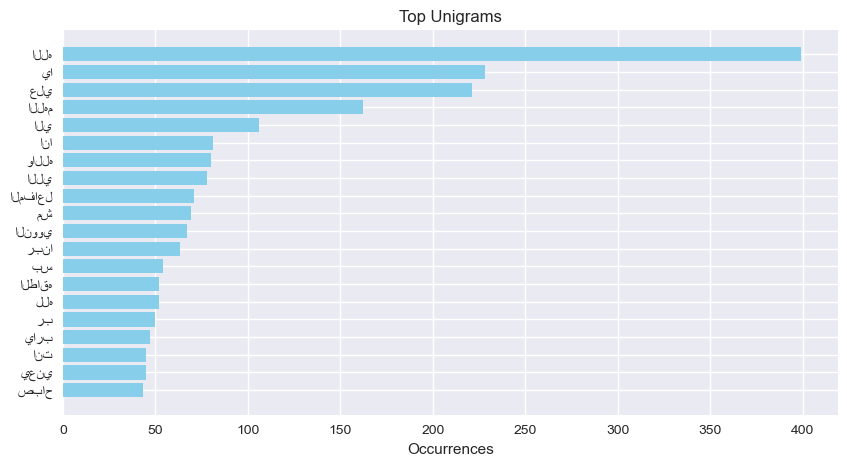

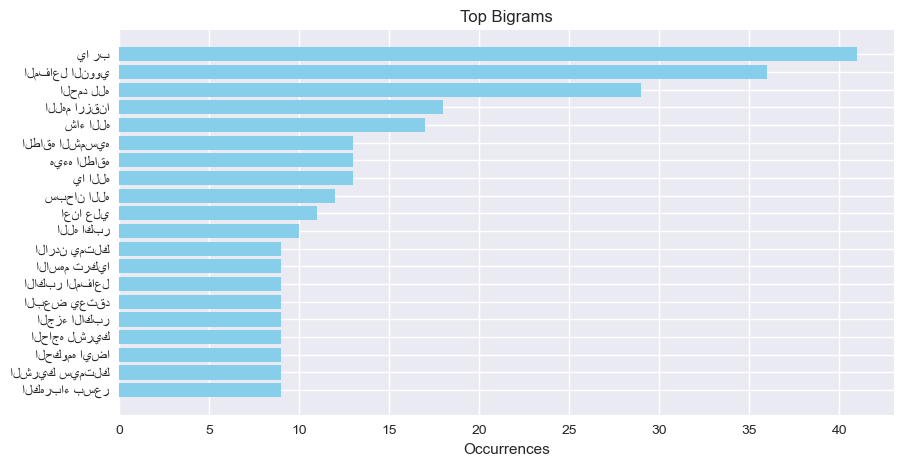

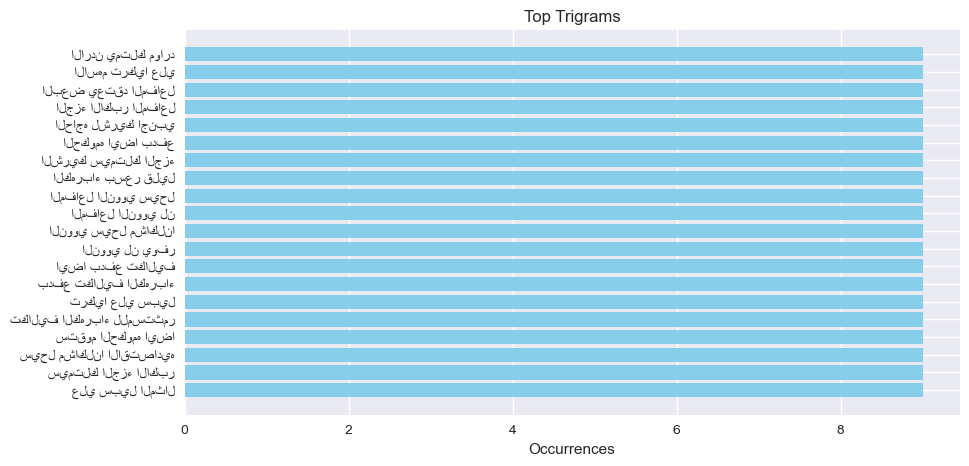

In [42]:
from sklearn.feature_extraction.text import CountVectorizer
import matplotlib.pyplot as plt

def plot_top_ngrams(corpus, ngram_range=(1,1), top=20, min_df=2, max_features=40000, title="Top n-grams"):
    """
    Affiche les n-grams les plus fréquents dans le corpus.
    """
    vectorizer = CountVectorizer(
        ngram_range=ngram_range,
        min_df=min_df,
        max_features=max_features,
        tokenizer=lambda x: x.split()  # tokenisation simple, comme dans ta vectorisation
    )
    X = vectorizer.fit_transform(corpus)
    
    # Somme des occurrences
    counts = X.sum(axis=0).A1
    vocab = vectorizer.get_feature_names_out()
    
    # Top n
    freq = list(zip(vocab, counts))
    freq = sorted(freq, key=lambda x: x[1], reverse=True)[:top]

    labels, values = zip(*freq)
    
    # Plot
    plt.figure(figsize=(10,5))
    plt.barh(labels, values, color='skyblue')
    plt.gca().invert_yaxis()
    plt.title(title)
    plt.xlabel("Occurrences")
    plt.show()


# --- Visualiser les unigrams ---
plot_top_ngrams(df["clean_text"], ngram_range=(1,1), top=20, title="Top Unigrams")

# --- Visualiser les bigrams ---
plot_top_ngrams(df["clean_text"], ngram_range=(2,2), top=20, title="Top Bigrams")

# --- Visualiser les trigrams ---
plot_top_ngrams(df["clean_text"], ngram_range=(3,3), top=20, title="Top Trigrams")


## Nuage de mots (Word Cloud) du corpus prétraité

En complément des graphiques N-grams, un **nuage de mots (Word Cloud)** est généré
afin de proposer une visualisation globale et intuitive du vocabulaire dominant
dans l’ensemble du corpus après nettoyage linguistique.


Cette visualisation offre une synthèse qualitative complémentaire aux mesures
quantitatives basées sur les N-grams.


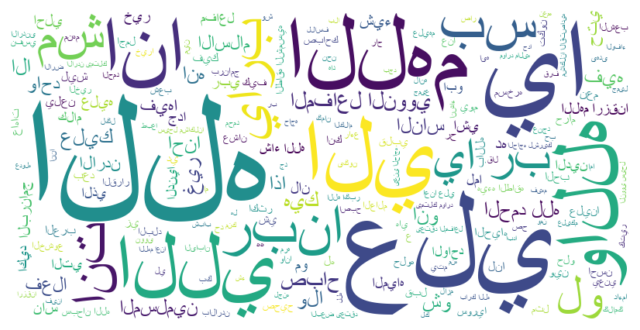

In [43]:
from wordcloud import WordCloud

text = " ".join(df["clean_text"])

wc = WordCloud(width=800, height=400, background_color="white", font_path="arial.ttf").generate(text)
plt.imshow(wc, interpolation='bilinear')
plt.axis("off")
plt.show()


## Implémentation du classifieur Naive Bayes *from scratch*

Dans cette partie, nous avons développé notre **propre implémentation du modèle Multinomial Naive Bayes** sans utiliser directement les outils de classification de *scikit-learn*.  
Cette implémentation a pour objectif de :

- Comprendre en profondeur le fonctionnement de l’algorithme.
- Vérifier la cohérence des résultats obtenus avec ceux de la méthode Sklearn.
- Comparer les performances entre une version personnalisée et une version industrielle optimisée.

---

Cette implémentation permet ainsi une comparaison directe avec le modèle
`MultinomialNB` de **Scikit-learn**, afin d’évaluer l’exactitude de notre approche manuelle.


In [44]:
import numpy as np

class MyMultinomialNB:
    def __init__(self, alpha=1.0):
        self.alpha = alpha
    
    def fit(self, X, y):
        y = np.array(y)
        self.classes = np.unique(y)
        n_features = X.shape[1]
        
        self.class_count = {}
        self.feature_count = {}
        self.log_priors = {}
        self.log_likelihoods = {}
        
        for c in self.classes:
            idx = (y == c)
            X_c = X[idx]

            # total occurrences of all words in class c
            self.class_count[c] = X_c.sum()

            # occurrences par feature
            self.feature_count[c] = np.array(X_c.sum(axis=0)).flatten()

            # P(c) = count(c) / N
            self.log_priors[c] = np.log(np.mean(y == c))

            # P(w|c)
            self.log_likelihoods[c] = np.log(
                (self.feature_count[c] + self.alpha) /
                (self.class_count[c] + self.alpha * n_features)
            )
    
    def predict(self, X):
        preds = []
        
        for i in range(X.shape[0]):
            x = X[i].toarray().flatten()
            scores = {}

            for c in self.classes:
                scores[c] = self.log_priors[c] + x @ self.log_likelihoods[c]

            preds.append(max(scores, key=scores.get))
        
        return np.array(preds)
    
    def predict_proba(self, X):

        probs = []

        for i in range(X.shape[0]):
            x = X[i].toarray().flatten()
            scores = []

            # calcul des log-scores
            for c in self.classes:
                score = self.log_priors[c] + x @ self.log_likelihoods[c]
                scores.append(score)

            # transformation en probabilités (softmax)
            scores = np.array(scores)
            exp_scores = np.exp(scores - scores.max())
            probs.append(exp_scores / exp_scores.sum())

        return np.array(probs)


Entraînement et prédiction avec Naive Bayes personnalisé

 Entraîne un Naive Bayes avec lissage, fait des prédictions et calcule les probabilités pour les courbes ROC/PR

In [45]:
nb = MyMultinomialNB(alpha=0.3 )
nb.fit(X_train_tfidf, y_train)
y_pred_nb = nb.predict(X_test_tfidf)
proba_nb = nb.predict_proba(X_test_tfidf)[:, 1] 



## Évaluation du modèle Naive Bayes

Après l’entraînement du classifieur Naive Bayes, nous procédons à l’**évaluation de ses performances** à l’aide de métriques standards en classification supervisée 


Cette analyse permet de mesurer précisément la capacité du classifieur
Naive Bayes à détecter les sentiments positifs et négatifs dans les tweets arabes.


Accuracy: 0.8400
Precision: 0.8542

Classification Report:
              precision    recall  f1-score   support

    Negative       0.83      0.86      0.84       200
    Positive       0.85      0.82      0.84       200

    accuracy                           0.84       400
   macro avg       0.84      0.84      0.84       400
weighted avg       0.84      0.84      0.84       400



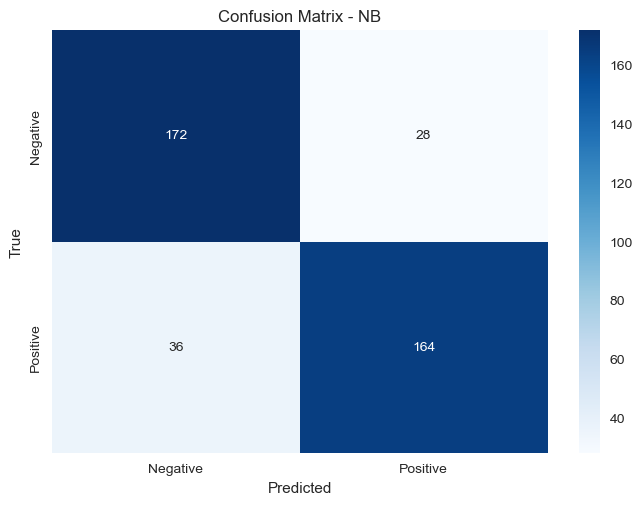

In [46]:
from sklearn.metrics import accuracy_score, precision_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

accuracy_nb = accuracy_score(y_test, y_pred_nb)
precision_nb = precision_score(y_test, y_pred_nb, pos_label="Positive")

print(f"Accuracy: {accuracy_nb:.4f}")
print(f"Precision: {precision_nb:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

# Matrice de confusion avec labels extraits automatiquement
labels_unique = sorted(y_test.unique())

cm_nb = confusion_matrix(y_test, y_pred_nb, labels=labels_unique)

sns.heatmap(cm_nb, annot=True, fmt="d",
            xticklabels=labels_unique, yticklabels=labels_unique,
            cmap="Blues")
plt.title("Confusion Matrix - NB")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

## Implémentation du classifieur Multinomial Naive Bayes avec Scikit-Learn

Après avoir développé notre propre implémentation du **Multinomial Naive Bayes** à partir des équations théoriques, nous utilisons maintenant la version **officielle proposée par la bibliothèque *Scikit-Learn*** afin de :

- Vérifier la cohérence et la validité de notre implémentation personnalisée.
- Comparer les performances en termes de précision, rappel et F1-score.
- Mesurer les écarts entre une implémentation manuelle et une implémentation optimisée standard.


In [47]:

from sklearn.naive_bayes import MultinomialNB

print(" Entraînement Naive Bayes (Sklearn)...")

sk_nb = MultinomialNB(alpha=1.0)
sk_nb.fit(X_train_tfidf, y_train)

# Prédictions
y_pred_sk = sk_nb.predict(X_test_tfidf)

# Probabilités
proba_sk = sk_nb.predict_proba(X_test_tfidf)[:, 1]

print(" Sklearn NB terminé")


 Entraînement Naive Bayes (Sklearn)...
 Sklearn NB terminé


In [48]:
from sklearn.metrics import classification_report

print("\n===== NAIVE BAYES SKLEARN =====")
print(classification_report(y_test, y_pred_sk))



===== NAIVE BAYES SKLEARN =====
              precision    recall  f1-score   support

    Negative       0.83      0.86      0.85       200
    Positive       0.86      0.83      0.84       200

    accuracy                           0.84       400
   macro avg       0.85      0.84      0.84       400
weighted avg       0.85      0.84      0.84       400




# ÉVALUATION DES MODÈLES (CUSTOM NB VS SKLEARN NB)

In [49]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

def metrics(y_true, y_pred):
    return [
        accuracy_score(y_true, y_pred),
        precision_score(y_true, y_pred, pos_label="Positive"),
        recall_score(y_true, y_pred, pos_label="Positive"),
        f1_score(y_true, y_pred, pos_label="Positive")
    ]

results = pd.DataFrame({
    "Custom NB"  : metrics(y_test, y_pred_nb),
    "Sklearn NB": metrics(y_test, y_pred_sk)
},
index=["Accuracy", "Precision", "Recall", "F1-score"])

print(results)


           Custom NB  Sklearn NB
Accuracy    0.840000     0.84500
Precision   0.854167     0.85567
Recall      0.820000     0.83000
F1-score    0.836735     0.84264



# COURBE ROC ET AUC POUR NAIVE BAYES (CUSTOM VS SKLEARN)


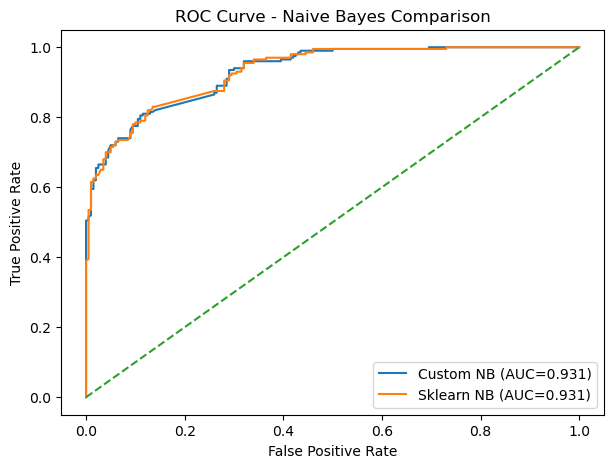

In [15]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fpr_custom, tpr_custom, _ = roc_curve(y_test, proba_nb, pos_label="Positive")
fpr_sk, tpr_sk, _ = roc_curve(y_test, proba_sk, pos_label="Positive")

auc_custom = auc(fpr_custom, tpr_custom)
auc_sk = auc(fpr_sk, tpr_sk)

plt.figure(figsize=(7,5))
plt.plot(fpr_custom, tpr_custom, label=f"Custom NB (AUC={auc_custom:.3f})")
plt.plot(fpr_sk, tpr_sk, label=f"Sklearn NB (AUC={auc_sk:.3f})")
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Naive Bayes Comparison")
plt.legend()
plt.show()



# MATRICES DE CONFUSION ET VISUALISATION

 Ce bloc de code calcule et affiche les matrices de confusion 
 pour le Naive Bayes personnalisé et le Naive Bayes de Sklearn.
Il affiche également une visualisation côte à côte des deux matrices.


===== MATRICE CONFUSION - NB PERSONNALISÉ =====
[[172  28]
 [ 36 164]]

===== MATRICE CONFUSION - NB SKLEARN =====
[[172  28]
 [ 34 166]]


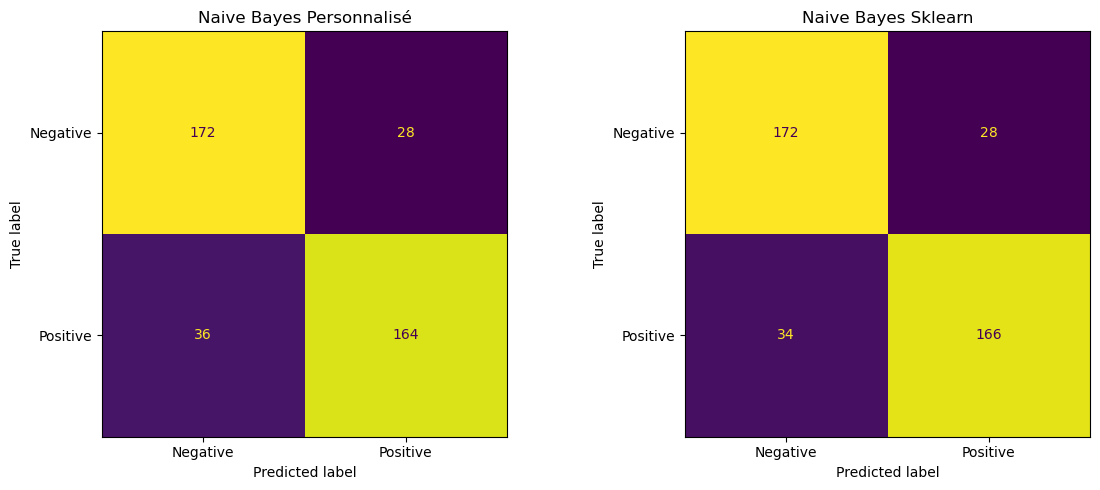

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# =============================
# MATRICES DE CONFUSION
# =============================

# Custom NB
cm_custom = confusion_matrix(
    y_test, 
    y_pred_nb, 
    labels=["Negative", "Positive"]
)

# Sklearn NB
cm_sklearn = confusion_matrix(
    y_test, 
    y_pred_sk,
    labels=["Negative", "Positive"]
)

print("===== MATRICE CONFUSION - NB PERSONNALISÉ =====")
print(cm_custom)

print("\n===== MATRICE CONFUSION - NB SKLEARN =====")
print(cm_sklearn)


# =============================
# VISUALISATION
# =============================

fig, ax = plt.subplots(1, 2, figsize=(12,5))

ConfusionMatrixDisplay(
    cm_custom,
    display_labels=["Negative", "Positive"]
).plot(ax=ax[0], values_format="d", colorbar=False)

ax[0].set_title("Naive Bayes Personnalisé")

ConfusionMatrixDisplay(
    cm_sklearn,
    display_labels=["Negative", "Positive"]
).plot(ax=ax[1], values_format="d", colorbar=False)

ax[1].set_title("Naive Bayes Sklearn")

plt.tight_layout()
plt.show()



# ADABOOST OPTIMISÉ AVEC WEAK STUMPS

Ce bloc définit deux classes principales :

1. WeakStumpOptimized : un classifieur faible basé sur un seuil 
   pour chaque feature, avec polarité optimisée.

 2. MyAdaBoostOptimized : implémentation personnalisée de l'AdaBoost,
   utilisant WeakStumpOptimized comme classifieur faible.


 Ce modèle gère également les poids des échantillons et la combinaison
 des stumps faibles via des coefficients alpha pondérés.


In [18]:
import numpy as np

class WeakStumpOptimized:
    def __init__(self):
        self.feature_id = None
        self.polarity = 1
        self.threshold = 0

    def fit(self, X, y, sample_weights):
        n_samples, n_features = X.shape
        y = np.array(y)

        best_feature = None
        best_threshold = None
        best_polarity = 1
        min_error = float("inf")

        for f in range(n_features):
            feature_values = X[:, f].toarray().flatten()
            thresholds = np.unique(feature_values)

            for thr in thresholds:
                preds = np.ones(n_samples)
                preds[feature_values <= thr] = -1
                error = np.sum(sample_weights * (preds != y))

                preds_inv = -preds
                error_inv = np.sum(sample_weights * (preds_inv != y))

                # Choisir la meilleure polarité et seuil
                if error < min_error:
                    min_error = error
                    best_feature = f
                    best_threshold = thr
                    best_polarity = 1
                if error_inv < min_error:
                    min_error = error_inv
                    best_feature = f
                    best_threshold = thr
                    best_polarity = -1

        self.feature_id = best_feature
        self.threshold = best_threshold
        self.polarity = best_polarity

        return min_error

    def predict(self, X):
        feature_values = X[:, self.feature_id].toarray().flatten()
        preds = np.ones(len(feature_values))
        preds[feature_values <= self.threshold] = -1
        return preds * self.polarity


class MyAdaBoostOptimized:
    def __init__(self, n_estimators=200, learning_rate=0.7):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.models = []
        self.alphas = []

    def fit(self, X, y):
        y_binary = np.where(y == "Positive", 1, -1)
        n_samples = X.shape[0]
        w = np.ones(n_samples) / n_samples

        for _ in range(self.n_estimators):
            stump = WeakStumpOptimized()
            error = stump.fit(X, y_binary, w)
            error = np.clip(error, 1e-10, 1 - 1e-10)  # évite division par zéro

            alpha = self.learning_rate * 0.5 * np.log((1 - error) / error)

            preds = stump.predict(X)
            w *= np.exp(-alpha * y_binary * preds)
            w /= np.sum(w)

            self.models.append(stump)
            self.alphas.append(alpha)

    def predict(self, X):
        final = np.zeros(X.shape[0])
        for alpha, stump in zip(self.alphas, self.models):
            final += alpha * stump.predict(X)
        return np.where(final > 0, "Positive", "Negative")

    def predict_proba(self, X):
        final = np.zeros(X.shape[0])
        for alpha, stump in zip(self.alphas, self.models):
            final += alpha * stump.predict(X)

        prob_pos = 1 / (1 + np.exp(-final))
        prob_neg = 1 - prob_pos
        return np.vstack([prob_neg, prob_pos]).T


In [20]:
ada_opt = MyAdaBoostOptimized(n_estimators=150)
ada_opt.fit(X_train_tfidf, y_train)
y_pred_ada_opt = ada_opt.predict(X_test_tfidf)
proba_ada = ada_opt.predict_proba(X_test_tfidf)[:, 1]


# ÉVALUATION DU MODÈLE ADABOOST OPTIMISÉ

 Ce bloc de code permet de :
 1. Calculer l'accuracy du modèle AdaBoost optimisé.
 2. Afficher le rapport de classification détaillé (precision, recall, f1-score).
 3. Générer et visualiser la matrice de confusion à l'aide d'un heatmap Seaborn.
 
 Les classes considérées sont "Positive" et "Negative".


AdaBoost Optimized Accuracy : 0.7200

Classification Report:
              precision    recall  f1-score   support

    Negative       0.66      0.90      0.76       200
    Positive       0.84      0.54      0.66       200

    accuracy                           0.72       400
   macro avg       0.75      0.72      0.71       400
weighted avg       0.75      0.72      0.71       400



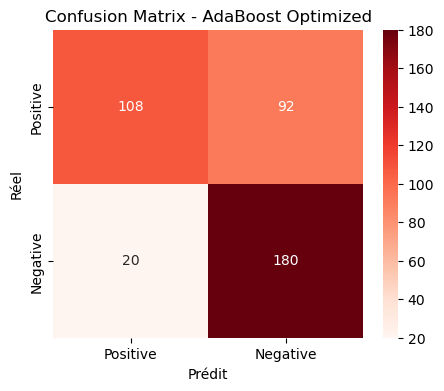

In [21]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

accuracy_ada_opt = accuracy_score(y_test, y_pred_ada_opt)
print(f"AdaBoost Optimized Accuracy : {accuracy_ada_opt:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_ada_opt))

cm_ada_opt = confusion_matrix(y_test, y_pred_ada_opt, labels=["Positive","Negative"])
plt.figure(figsize=(5,4))
sns.heatmap(cm_ada_opt, annot=True, fmt="d", xticklabels=["Positive","Negative"], yticklabels=["Positive","Negative"], cmap="Reds")
plt.title("Confusion Matrix - AdaBoost Optimized")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.show()

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import train_test_split

# 1. Vectorisation du texte
tfidf = TfidfVectorizer()
X_tfidf = tfidf.fit_transform(df['clean_text'])   # text → vecteurs numériques

# 2. Split
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf, df['label'], test_size=0.2, random_state=42
)

# 3. AdaBoost
ada = AdaBoostClassifier(n_estimators=150)
ada.fit(X_train, y_train)

# 4. Prédiction
y_pred = ada.predict(X_test)




Ce bloc effectue l'évaluation complète du modèle AdaBoost :

 1. Calcul de l'accuracy sur les données de test.
 2. Affichage du rapport de classification (precision, recall, f1-score).
 3. Calcul et visualisation de la matrice de confusion avec Seaborn.
 4. Calcul de l'AUC (Area Under the Curve) si le modèle supporte predict_proba.
 5. Tracé de la courbe ROC pour visualiser la performance du modèle.


🔹 Accuracy : 0.735

🔹 Classification Report :
              precision    recall  f1-score   support

    Negative       0.66      0.96      0.78       201
    Positive       0.92      0.51      0.66       199

    accuracy                           0.73       400
   macro avg       0.79      0.73      0.72       400
weighted avg       0.79      0.73      0.72       400



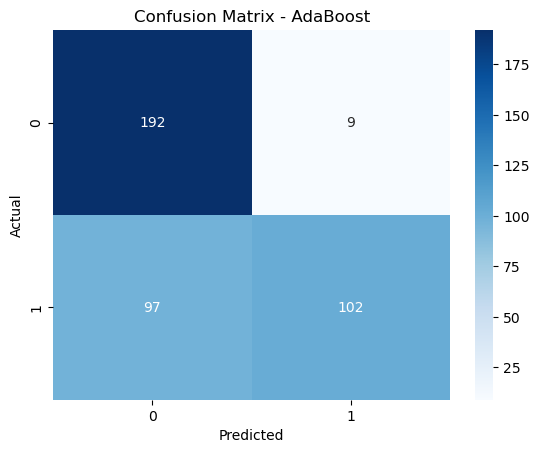


🔹 AUC : 0.7985449636240907


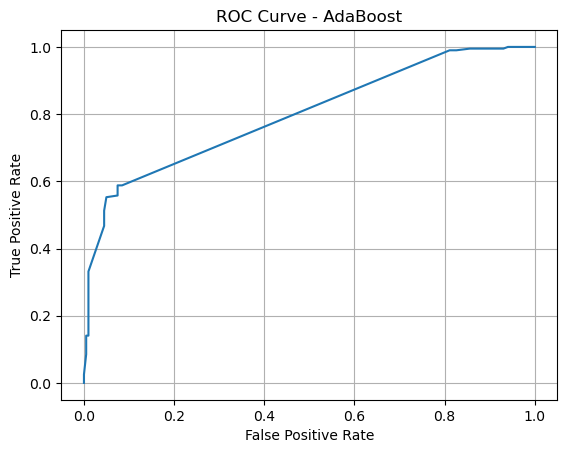

In [23]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)
import matplotlib.pyplot as plt

# 1. Accuracy
print("🔹 Accuracy :", accuracy_score(y_test, y_pred))

# 2. Précision, Rappel, F1-score
print("\n🔹 Classification Report :")
print(classification_report(y_test, y_pred))

# 3. Matrice de confusion
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - AdaBoost")
plt.show()

# 4. AUC (si ton modèle supporte predict_proba)
proba = ada.predict_proba(X_test)[:, 1]
print("\n🔹 AUC :", roc_auc_score(y_test, proba))

# 5. Courbe ROC
fpr, tpr, _ = roc_curve(y_test, proba, pos_label="Positive")

plt.plot(fpr, tpr)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - AdaBoost")
plt.grid()
plt.show()


# COMPARAISON DE L'ACCURACY : NB PERSONNALISÉ VS ADABOOST OPTIMISÉ

 Ce bloc crée un tableau et un graphique en barres pour comparer l'accuracy :
 - Naive Bayes personnalisé
 - AdaBoost Optimisé


                Modele  Accuracy
0      NB personnalisé      0.84
1   AdaBoost Optimized      0.72


C:\Users\em\AppData\Local\Temp\ipykernel_11044\1262114572.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Modele", y="Accuracy", data=comparison, palette=["blue", "red"])


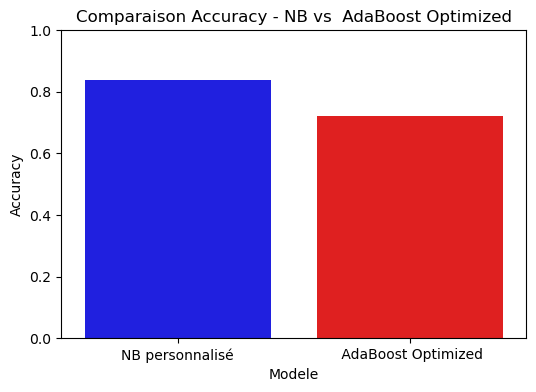

In [24]:

import pandas as pd

comparison = pd.DataFrame({
    "Modele": ["NB personnalisé", " AdaBoost Optimized"],
    "Accuracy": [accuracy_nb,accuracy_ada_opt]
})
print(comparison)

plt.figure(figsize=(6,4))
sns.barplot(x="Modele", y="Accuracy", data=comparison, palette=["blue", "red"])
plt.ylim(0,1)
plt.title("Comparaison Accuracy - NB vs  AdaBoost Optimized")
plt.show()



Visualisation côte à côte des matrices de confusion

In [25]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_test_enc = le.fit_transform(y_test)

# Probabilités
proba_nb = nb.predict_proba(X_test_tfidf)[:, 1]      
proba_ada = ada_opt.predict_proba(X_test_tfidf)[:, 1]  

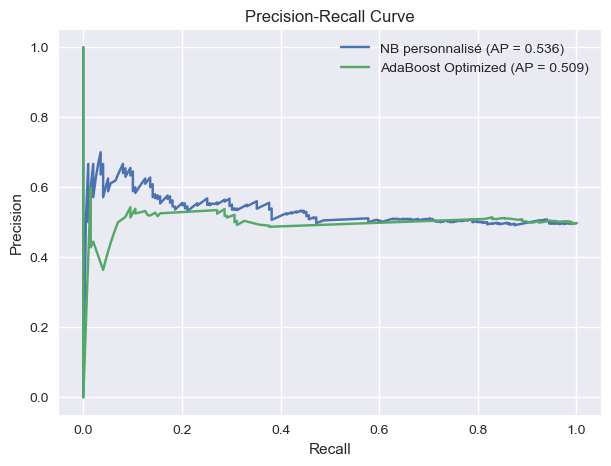

In [50]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Courbes PR
precision_nb, recall_nb, _ = precision_recall_curve(y_test_enc, proba_nb)
precision_ada, recall_ada, _ = precision_recall_curve(y_test_enc, proba_ada)

plt.figure(figsize=(7,5))
plt.plot(recall_nb, precision_nb, 
         label=f"NB personnalisé (AP = {average_precision_score(y_test_enc, proba_nb):.3f})")

plt.plot(recall_ada, precision_ada,
         label=f"AdaBoost Optimized (AP = {average_precision_score(y_test_enc, proba_ada):.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(True)
plt.show()



# COMPARAISON DES COURBES ROC

Ce bloc trace les courbes ROC pour comparer les performances :
- Naive Bayes (NB)
- AdaBoost



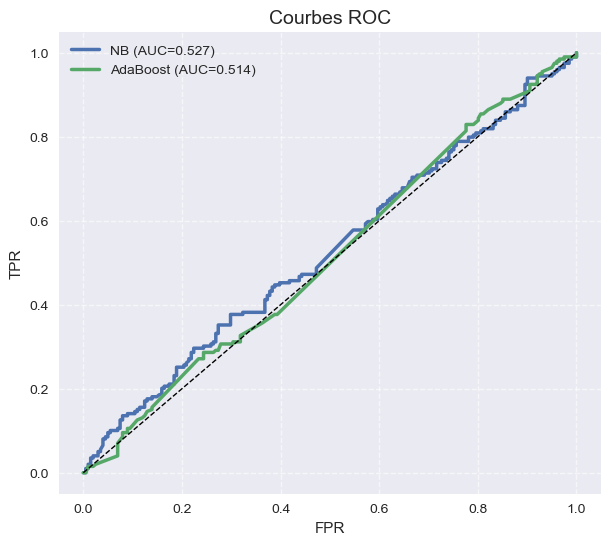

In [51]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

plt.style.use('seaborn-v0_8')

# ROC
fpr_nb, tpr_nb, _ = roc_curve(y_test_enc, proba_nb)
fpr_ada, tpr_ada, _ = roc_curve(y_test_enc, proba_ada)

auc_nb = auc(fpr_nb, tpr_nb)
auc_ada = auc(fpr_ada, tpr_ada)

plt.figure(figsize=(7,6))
plt.plot(fpr_nb, tpr_nb, linewidth=2.5, label=f"NB (AUC={auc_nb:.3f})")
plt.plot(fpr_ada, tpr_ada, linewidth=2.5, label=f"AdaBoost (AUC={auc_ada:.3f})")
plt.plot([0,1], [0,1], 'k--', linewidth=1)

plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("Courbes ROC", fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()




# COMPARAISON DES PERFORMANCES : NAIVE BAYES VS ADABOOST

Ce bloc calcule et affiche les métriques de performance pour les modèles :
- Naive Bayes (Sklearn)
- AdaBoost (Sklearn)
#
 Les résultats sont présentés sous forme de DataFrame pour une comparaison claire.


In [52]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)
import pandas as pd

def metrics_with_auc(y_true, y_pred, proba):
    return [
        accuracy_score(y_true, y_pred),
        precision_score(y_true, y_pred, pos_label="Positive"),
        recall_score(y_true, y_pred, pos_label="Positive"),
        f1_score(y_true, y_pred, pos_label="Positive"),
        roc_auc_score(y_true, proba)
    ]


comparison = pd.DataFrame({
    "Naive Bayes (sklearn)" : metrics_with_auc(y_test, y_pred_sk, proba_sk),
    "AdaBoost (sklearn)"    : metrics_with_auc(y_test, y_pred,     proba)
},
index=["Accuracy", "Precision", "Recall", "F1-score", "AUC"]
)

print("\n📊 COMPARAISON ENTRE NB (Sklearn) ET AdaBoost :\n")
print(comparison)



📊 COMPARAISON ENTRE NB (Sklearn) ET AdaBoost :

           Naive Bayes (sklearn)  AdaBoost (sklearn)
Accuracy                0.845000            0.492500
Precision               0.855670            0.486486
Recall                  0.830000            0.270000
F1-score                0.842640            0.347267
AUC                     0.931163            0.528112


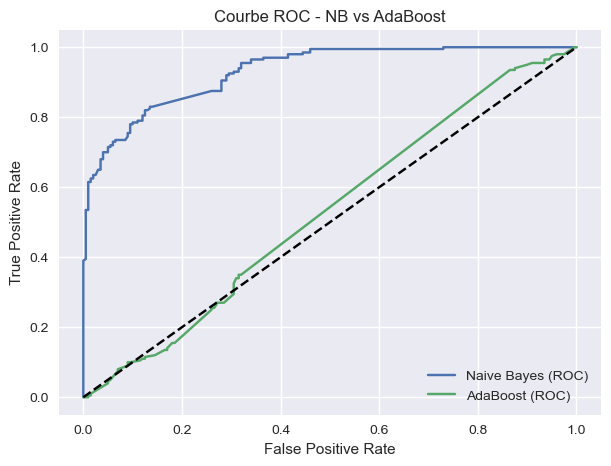

In [54]:

from sklearn.metrics import roc_curve, precision_recall_curve
import matplotlib.pyplot as plt

# ---------- ROC CURVE ----------
fpr_nb, tpr_nb, _ = roc_curve(y_test, proba_sk, pos_label="Positive")
fpr_ada, tpr_ada, _ = roc_curve(y_test, proba, pos_label="Positive")

plt.figure(figsize=(7, 5))
plt.plot(fpr_nb, tpr_nb, label="Naive Bayes (ROC)")
plt.plot(fpr_ada, tpr_ada, label="AdaBoost (ROC)")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Courbe ROC - NB vs AdaBoost")
plt.legend()
plt.grid(True)
plt.show()

